In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/elikplim/concrete-compressive-strength-data-set/concrete_data.csv


In [2]:

import pandas as pd
# Load the Concrete Compressive Strength dataset
df = pd.read_csv('/kaggle/input/datasets/elikplim/concrete-compressive-strength-data-set/concrete_data.csv')

# Display dataset information
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())


Dataset Shape: (1030, 9)

Column Names:
['cement', 'blast_furnace_slag', 'fly_ash', 'water', 'superplasticizer', 'coarse_aggregate', 'fine_aggregate ', 'age', 'concrete_compressive_strength']

First 5 Rows:


,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [3]:

import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# Step 1: Clean the dataset
df_clean = df.dropna().drop_duplicates().copy()

# Step 2: Separate features and target
X = df_clean.drop(columns=['concrete_compressive_strength'])
y = df_clean['concrete_compressive_strength']

# Step 3: Split data (80% training, 20% testing)
X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Step 4: Polynomial Features (degree = 2)
poly = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly = poly.fit_transform(X_train_raw)
X_test_poly = poly.transform(X_test_raw)

# Step 5: Feature Scaling
scaler_X = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train_poly)
X_test_scaled = scaler_X.transform(X_test_poly)

# Step 6: Target Scaling
scaler_y = StandardScaler()

y_train = scaler_y.fit_transform(
    y_train_raw.to_numpy().reshape(-1, 1)
).ravel()

y_test = scaler_y.transform(
    y_test_raw.to_numpy().reshape(-1, 1)
).ravel()

# Display results
print("Original Rows:", len(df))
print("Clean Rows:", len(df_clean))
print("Training Samples:", X_train_scaled.shape[0])
print("Testing Samples:", X_test_scaled.shape[0])
print("Polynomial Features:", X_train_scaled.shape[1])
print("Training Target Mean:", round(y_train.mean(), 4))


Original Rows: 1030
Clean Rows: 1005
Training Samples: 804
Testing Samples: 201
Polynomial Features: 44
Training Target Mean: 0.0


In [4]:

# Stochastic Gradient Descent (SGD) from Scratch

# Add bias column (x0 = 1)
X_train_sgd = np.c_[
    np.ones(X_train_scaled.shape[0]),
    X_train_scaled
]

# Initialize parameters
m_sgd, n_sgd = X_train_sgd.shape
theta_sgd = np.zeros(n_sgd)

# Hyperparameters
learning_rate_sgd = 0.0001
epochs_sgd = 2000

# Random generator for reproducibility
rng = np.random.default_rng(42)

# Store cost values
cost_history_sgd = []

# Calculate initial cost
initial_cost_sgd = np.mean(y_train ** 2) / 2

# SGD Training
for epoch in range(epochs_sgd):

    # Shuffle training examples
    indices = rng.permutation(m_sgd)

    # Update parameters using one example at a time
    for i in indices:

        prediction = X_train_sgd[i] @ theta_sgd

        error = prediction - y_train[i]

        gradient = error * X_train_sgd[i]

        theta_sgd -= learning_rate_sgd * gradient

    # Calculate full training cost after each epoch
    predictions = X_train_sgd @ theta_sgd
    cost = np.mean((predictions - y_train) ** 2) / 2

    cost_history_sgd.append(cost)

# Display results
print("Optimizer: Stochastic Gradient Descent")
print("Learning Rate:", learning_rate_sgd)
print("Epochs:", epochs_sgd)
print("Number of Parameters:", n_sgd)
print("Initial Cost:", round(initial_cost_sgd, 6))
print("Final Cost:", round(cost_history_sgd[-1], 6))


Optimizer: Stochastic Gradient Descent
Learning Rate: 0.0001
Epochs: 2000
Number of Parameters: 45
Initial Cost: 0.5
Final Cost: 0.105816


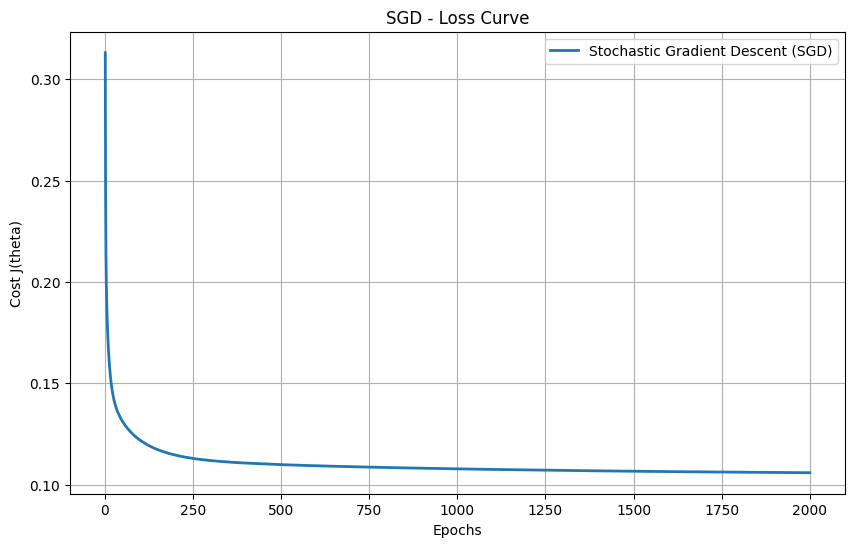

In [5]:

# Plot SGD Loss Curve

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    range(1, epochs_sgd + 1),
    cost_history_sgd,
    label='Stochastic Gradient Descent (SGD)',
    linewidth=2
)

plt.xlabel('Epochs')
plt.ylabel('Cost J(theta)')
plt.title('SGD - Loss Curve')
plt.legend()
plt.grid(True)
plt.show()


In [6]:

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Add bias column to test data
X_test_sgd = np.c_[
    np.ones(X_test_scaled.shape[0]),
    X_test_scaled
]

# Make predictions
y_pred_scaled_sgd = X_test_sgd @ theta_sgd

# Convert predictions to original scale
y_pred_sgd = scaler_y.inverse_transform(
    y_pred_scaled_sgd.reshape(-1, 1)
).ravel()

# Actual test values
y_actual = y_test_raw.to_numpy()

# Calculate evaluation metrics
mse_sgd = mean_squared_error(y_actual, y_pred_sgd)
rmse_sgd = np.sqrt(mse_sgd)
mae_sgd = mean_absolute_error(y_actual, y_pred_sgd)
r2_sgd = r2_score(y_actual, y_pred_sgd)

print("SGD - Test Results")
print("-------------------------")
print("MSE:", round(mse_sgd, 4))
print("RMSE:", round(rmse_sgd, 4))
print("MAE:", round(mae_sgd, 4))
print("R2 Score:", round(r2_sgd, 4))


SGD - Test Results
-------------------------
MSE: 68.3634
RMSE: 8.2682
MAE: 6.0612
R2 Score: 0.7708


In [7]:

# SGD with Momentum from Scratch

# Initialize parameters
theta_sgd_momentum = np.zeros(n_sgd)
velocity_sgd = np.zeros(n_sgd)

# Hyperparameters
beta_sgd = 0.9
learning_rate_momentum = 0.00001

# Use same random seed for reproducibility
rng_momentum = np.random.default_rng(42)

# Store cost values
cost_history_sgd_momentum = []

# Training
for epoch in range(epochs_sgd):

    indices = rng_momentum.permutation(m_sgd)

    for i in indices:

        prediction = X_train_sgd[i] @ theta_sgd_momentum
        error = prediction - y_train[i]

        gradient = error * X_train_sgd[i]

        # Momentum update
        velocity_sgd = (
            beta_sgd * velocity_sgd + gradient
        )

        # Update parameters
        theta_sgd_momentum -= (
            learning_rate_momentum * velocity_sgd
        )

    # Calculate training cost after each epoch
    predictions = X_train_sgd @ theta_sgd_momentum
    cost = np.mean((predictions - y_train) ** 2) / 2

    cost_history_sgd_momentum.append(cost)

# Evaluate on test data
y_pred_mom_scaled = X_test_sgd @ theta_sgd_momentum

y_pred_mom = scaler_y.inverse_transform(
    y_pred_mom_scaled.reshape(-1, 1)
).ravel()

rmse_sgd_momentum = np.sqrt(
    mean_squared_error(y_actual, y_pred_mom)
)

r2_sgd_momentum = r2_score(y_actual, y_pred_mom)

# Compare results
print("SGD vs SGD with Momentum")
print("--------------------------------")
print("SGD Final Cost:", round(cost_history_sgd[-1], 6))
print("Momentum Final Cost:", round(cost_history_sgd_momentum[-1], 6))

print("SGD Test RMSE:", round(rmse_sgd, 4))
print("Momentum Test RMSE:", round(rmse_sgd_momentum, 4))

print("SGD Test R2:", round(r2_sgd, 4))
print("Momentum Test R2:", round(r2_sgd_momentum, 4))


SGD vs SGD with Momentum
--------------------------------
SGD Final Cost: 0.105816
Momentum Final Cost: 0.105818
SGD Test RMSE: 8.2682
Momentum Test RMSE: 8.2703
SGD Test R2: 0.7708
Momentum Test R2: 0.7707


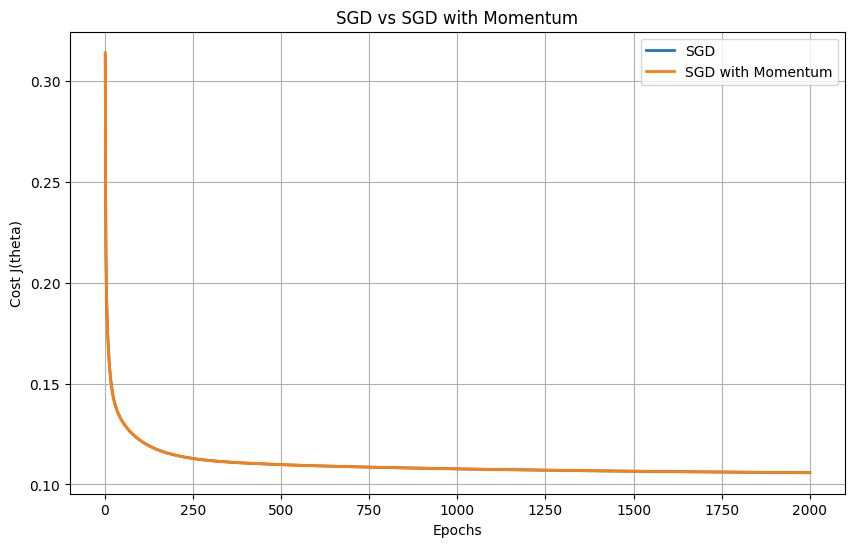

In [8]:

# Compare SGD and SGD with Momentum

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    range(1, epochs_sgd + 1),
    cost_history_sgd,
    label='SGD',
    linewidth=2
)

plt.plot(
    range(1, epochs_sgd + 1),
    cost_history_sgd_momentum,
    label='SGD with Momentum',
    linewidth=2
)

plt.xlabel('Epochs')
plt.ylabel('Cost J(theta)')
plt.title('SGD vs SGD with Momentum')
plt.legend()
plt.grid(True)
plt.show()



## Results and Discussion

In this experiment, Polynomial Regression (degree = 2) was trained using Stochastic Gradient Descent (SGD) and SGD with Momentum.

### Experimental Results

| Metric | SGD | SGD with Momentum |
|---|---|---|
| Final Training Cost | 0.105816 | 0.105818 |
| Test RMSE | 8.2682 | 8.2703 |
| Test R² | 0.7708 | 0.7707 |

### Discussion

SGD successfully reduced the training cost over 2000 epochs by updating the model parameters using one training example at a time.

Momentum was implemented with beta = 0.9 to incorporate information from previous gradients.

The loss curves were nearly identical, indicating similar convergence behavior under the selected settings.

SGD achieved a slightly lower final cost and test RMSE than SGD with Momentum. However, the differences were very small.

Different learning rates were used, so the results cannot be attributed to Momentum alone.

### Conclusion

Both SGD and SGD with Momentum successfully optimized the Polynomial Regression model.

In this experiment, adding Momentum did not produce a meaningful improvement in predictive performance.

The effectiveness of Momentum depends on the learning rate and other training settings.
